In [60]:
import pvlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

print("PVLIB:", pvlib.__version__)
print("NumPy:", np.__version__)
print("Pandas:", pd.__version__)

print("Balikesir agrivoltaik projesi basladi!")

PVLIB: 0.16.1
NumPy: 2.5.5
Pandas: 3.1.1
Balikesir agrivoltaik projesi basladi!


In [61]:
# Balikesir merkez koordinatlari

LAT = 39.6484
LON = 27.8826

print("Enlem:", LAT)
print("Boylam:", LON)

Enlem: 39.6484
Boylam: 27.8826


In [62]:
# BALIKESIR - PVGIS METEOROLOJIK VERI INDIRME

# PVGIS uzerinden tipik meteorolojik yil verisini indiriyoruz

weather, meta = pvlib.iotools.get_pvgis_tmy(

    latitude=LAT,

    longitude=LON,

    outputformat="json",

    map_variables=True,

    url="https://re.jrc.ec.europa.eu/api/v5_2/",

    timeout=120
)

print("PVGIS veri indirme tamamlandi!")

print("Veri boyutu:", weather.shape)

print("Veri sutunlari:")

print(weather.columns.tolist())


PVGIS veri indirme tamamlandi!
Veri boyutu: (8760, 9)
Veri sutunlari:
['temp_air', 'relative_humidity', 'ghi', 'dni', 'dhi', 'IR(h)', 'wind_speed', 'wind_direction', 'pressure']


In [63]:
# VERI KONTROLU

print("Toplam saat:", len(weather))

print("\nIlk 5 saatlik veri:")

display(weather.head())

print("\nEksik veri kontrolu:")

print(weather[
    ["ghi", "dni", "dhi", "temp_air", "wind_speed"]
].isnull().sum())

if len(weather) == 8760:

    print("\nBASARILI: 8760 saatlik veri alindi!")

else:

    print("\nKontrol gerekli. Saat sayisi:", len(weather))

Toplam saat: 8760

Ilk 5 saatlik veri:


,temp_air,relative_humidity,ghi,dni,dhi,IR(h),wind_speed,wind_direction,pressure
time(UTC),,,,,,,,,
1990-01-01 00:00:00+00:00,1.65,89.96,0.0,0.0,0.0,294.43,3.00,16.0,100315.0
1990-01-01 01:00:00+00:00,2.47,91.54,0.0,0.0,0.0,303.81,2.74,18.0,100305.0
1990-01-01 02:00:00+00:00,3.29,93.11,0.0,0.0,0.0,313.19,2.49,19.0,100266.0
1990-01-01 03:00:00+00:00,4.10,94.69,0.0,0.0,0.0,322.57,2.23,19.0,100236.0
1990-01-01 04:00:00+00:00,4.92,96.26,0.0,0.0,0.0,331.95,1.98,21.0,100236.0



Eksik veri kontrolu:
ghi           0
dni           0
dhi           0
temp_air      0
wind_speed    0
dtype: int64

BASARILI: 8760 saatlik veri alindi!


In [64]:
# VERILERI BILGISAYARA KAYDET

import json

# Proje klasörünü bul
project_dir = Path.cwd()

if not (project_dir / "requirements.txt").exists():
    project_dir = project_dir.parent

# Veri klasörü
data_dir = project_dir / "data" / "raw"

data_dir.mkdir(parents=True, exist_ok=True)

# CSV dosyası
weather.to_csv(
    data_dir / "balikesir_tmy.csv",
    index_label="time_utc"
)

# Metadata dosyası
with open(
    data_dir / "balikesir_tmy_metadata.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        meta,
        f,
        ensure_ascii=False,
        indent=4,
        default=str
    )

print("Meteorolojik veri kaydedildi!")

print("Dosya konumu:", data_dir)


Meteorolojik veri kaydedildi!
Dosya konumu: c:\Users\Asus\Desktop\Agrivoltaik_Balikesir\data\raw


In [65]:
# METEOROLOJIK VERI KONTROLU

print("Toplam saat sayisi:", len(weather))

print("\nVeri sutunlari:")
print(weather.columns.tolist())

# Gerekli sütunları kontrol et
required = [
    "ghi",
    "dni",
    "dhi",
    "temp_air",
    "wind_speed"
]

print("\nIlk 5 saatlik veri:")

display(weather[required].head())

print("\nEksik veri sayilari:")

print(weather[required].isnull().sum())

if len(weather) == 8760:
    print("\nBASARILI: 8760 saatlik veri mevcut!")
else:
    print("\nSaat sayisini kontrol et:", len(weather))

Toplam saat sayisi: 8760

Veri sutunlari:
['temp_air', 'relative_humidity', 'ghi', 'dni', 'dhi', 'IR(h)', 'wind_speed', 'wind_direction', 'pressure']

Ilk 5 saatlik veri:


,ghi,dni,dhi,temp_air,wind_speed
time(UTC),,,,,
1990-01-01 00:00:00+00:00,0.0,0.0,0.0,1.65,3.00
1990-01-01 01:00:00+00:00,0.0,0.0,0.0,2.47,2.74
1990-01-01 02:00:00+00:00,0.0,0.0,0.0,3.29,2.49
1990-01-01 03:00:00+00:00,0.0,0.0,0.0,4.10,2.23
1990-01-01 04:00:00+00:00,0.0,0.0,0.0,4.92,1.98



Eksik veri sayilari:
ghi           0
dni           0
dhi           0
temp_air      0
wind_speed    0
dtype: int64

BASARILI: 8760 saatlik veri mevcut!


In [66]:
# BALIKESIR - GUNES KONUMU HESAPLAMASI

# Balikesir konumunu tanimla

site = pvlib.location.Location(
    latitude=LAT,
    longitude=LON,
    tz="UTC",
    name="Balikesir"
)

# Gunesin konumunu hesapla

solar_position = site.get_solarposition(
    weather.index,
    temperature=weather["temp_air"]
)

# Sonuclari ekrana yazdir

print("Gunes konumu hesaplandi!")

print("Toplam saat:", len(solar_position))

print("\nGunes konumu sutunlari:")

print(solar_position.columns.tolist())

print("\nIlk 5 saatlik sonuc:")

display(
    solar_position[[
        "apparent_zenith",
        "zenith",
        "azimuth",
        "apparent_elevation"
    ]].head()
)

Gunes konumu hesaplandi!
Toplam saat: 8760

Gunes konumu sutunlari:
['apparent_zenith', 'zenith', 'apparent_elevation', 'elevation', 'azimuth', 'equation_of_time']

Ilk 5 saatlik sonuc:


,apparent_zenith,zenith,azimuth,apparent_elevation
time(UTC),,,,
1990-01-01 00:00:00+00:00,151.731412,151.731412,62.114918,-61.731412
1990-01-01 01:00:00+00:00,140.881116,140.881116,77.678174,-50.881116
1990-01-01 02:00:00+00:00,129.427779,129.427779,88.658539,-39.427779
1990-01-01 03:00:00+00:00,117.912095,117.912095,97.820083,-27.912095
1990-01-01 04:00:00+00:00,106.633020,106.633020,106.422487,-16.633020


FileNotFoundError: [Errno 2] No such file or directory: 'results/balikesir_gunes_konumu.png'

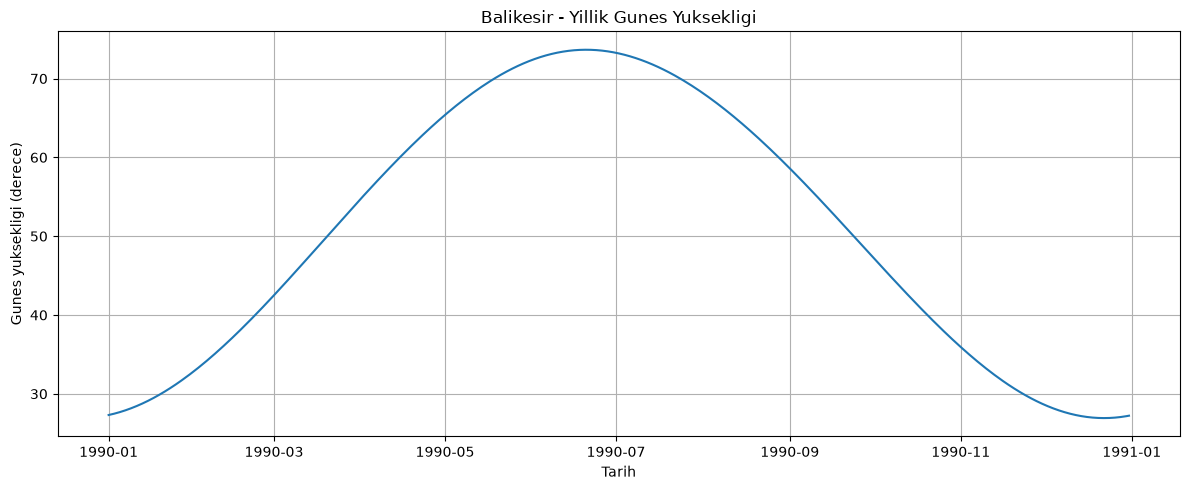

In [67]:
# GUNES YUKSEKLIGININ YILLIK DEGISIMI

daily_elevation = (
    solar_position["apparent_elevation"]
    .resample("D")
    .max()
)

plt.figure(figsize=(12, 5))

plt.plot(
    daily_elevation.index,
    daily_elevation.values
)

plt.xlabel("Tarih")
plt.ylabel("Gunes yuksekligi (derece)")

plt.title(
    "Balikesir - Yillik Gunes Yuksekligi"
)

plt.grid()
plt.tight_layout()

plt.savefig(
    "results/balikesir_gunes_konumu.png",
    dpi=300
)

plt.show()

In [ ]:
import os

# Eğer çalışma dizini 'notebooks' ise bir üst dizine (ana proje klasörüne) geç
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
    

In [ ]:
import os
from pathlib import Path

# Çalışma dizini 'notebooks' içindeyse ana proje klasörüne çık
if os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

# Gerekli tüm klasörleri otomatik oluştur (hata almamak için)
Path("results").mkdir(parents=True, exist_ok=True)
Path("figures").mkdir(parents=True, exist_ok=True)
Path("data/raw").mkdir(parents=True, exist_ok=True)

print("Aktif çalışma dizini:", os.getcwd())

In [ ]:
solar_position.to_csv(
    "results/balikesir_solar_position.csv",
    index_label="time_utc"
)

print("Gunes konumu verileri kaydedildi!")

In [ ]:
# AGRIVOLTAIK PANEL GEOMETRISI

# Panel ozellikleri

TILT = 25

AZIMUTH = 180

MODULE_WIDTH = 2.2

CENTER_HEIGHT = 3.0

ALBEDO = 0.20

BIFACIALITY = 0.75

# Uc farkli sira araligi

PITCHES = [5.0, 7.0, 9.0]

print("Panel geometrisi tanimlandi!")

print("Panel egimi:", TILT)

print("Panel yonu:", AZIMUTH)

print("Panel uzunlugu:", MODULE_WIDTH)

print("Panel yuksekligi:", CENTER_HEIGHT)

print("Sira araliklari:", PITCHES)

In [ ]:
# GCR HESAPLAMASI

geometry = pd.DataFrame({
    "Pitch_m": PITCHES
})

geometry["Panel_length_m"] = MODULE_WIDTH

geometry["GCR"] = (
    geometry["Panel_length_m"] /
    geometry["Pitch_m"]
)

display(geometry.round(3))




NameError: name 'PITCHES' is not defined

In [ ]:
# GCR HESAPLAMASI - TAM KOD

import pandas as pd

# Panel özellikleri
TILT = 25
AZIMUTH = 180
MODULE_WIDTH = 2.2
CENTER_HEIGHT = 3.0

ALBEDO = 0.20
BIFACIALITY = 0.75

# Sıra aralıkları
PITCHES = [5.0, 7.0, 9.0]

# GCR tablosu
geometry = pd.DataFrame({
    "Sira araligi (m)": PITCHES
})

geometry["Panel uzunlugu (m)"] = MODULE_WIDTH

geometry["GCR"] = (
    MODULE_WIDTH / geometry["Sira araligi (m)"]
)

print("PANEL GEOMETRISI")
print(geometry.round(3).to_string(index=False))

In [ ]:
print("MERHABA BALIKESIR!")
print("Python kodum calisiyor!")

In [ ]:
# GCR HESAPLAMASI - TAM KOD

import pandas as pd

# Panel özellikleri
TILT = 25
AZIMUTH = 180
MODULE_WIDTH = 2.2
CENTER_HEIGHT = 3.0

ALBEDO = 0.20
BIFACIALITY = 0.75

# Sıra aralıkları
PITCHES = [5.0, 7.0, 9.0]

# GCR tablosu
geometry = pd.DataFrame({
    "Sira araligi (m)": PITCHES
})

geometry["Panel uzunlugu (m)"] = MODULE_WIDTH

geometry["GCR"] = (
    MODULE_WIDTH / geometry["Sira araligi (m)"]
)

print("PANEL GEOMETRISI")
print(geometry.round(3).to_string(index=False))


PANEL GEOMETRISI
 Sira araligi (m)  Panel uzunlugu (m)   GCR
              5.0                 2.2 0.440
              7.0                 2.2 0.314
              9.0                 2.2 0.244


In [ ]:
print(2 + 2)
print("Python calisiyor")


4
Python calisiyor


In [ ]:
print("TEST")


TEST


In [ ]:
# PANEL ISINIM KARSILASTIRMA GRAFIGI

import matplotlib.pyplot as plt
import numpy as np

plot_df = irradiance_summary.sort_values("Sira_araligi_m")

x = np.arange(len(plot_df))
width = 0.24

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(
    x - width,
    plot_df["On_yuz_W_m2"],
    width,
    label="Panel on yuz"
)

ax.bar(
    x,
    plot_df["Arka_yuz_W_m2"],
    width,
    label="Panel arka yuz"
)

ax.bar(
    x + width,
    plot_df["Toplam_W_m2"],
    width,
    label="Toplam etkin isinim"
)

ax.set_xlabel("Panel sira araligi (m)")
ax.set_ylabel("Ortalama isinim (W/m2)")

ax.set_title("Panel Sira Araliginin Isinima Etkisi")

ax.set_xticks(x)
ax.set_xticklabels(
    [f"{p:g} m" for p in plot_df["Sira_araligi_m"]]
)

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()

figures_dir = project_dir / "figures"
figures_dir.mkdir(parents=True, exist_ok=True)

plt.savefig(
    figures_dir / "panel_isinim_karsilastirmasi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:
print("TEST BASARILI!")

In [ ]:
from pathlib import Path

# results klasörünü oluştur
Path("results").mkdir(parents=True, exist_ok=True)

print("Results klasoru hazir!")

In [ ]:
from pathlib import Path

# Bir üst dizindeki (ana klasördeki) results klasörünü hedefler
Path("../results").mkdir(parents=True, exist_ok=True)

print("Results klasoru hazir!")
